In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
df = pd.read_csv(url)
df.to_csv("telco_churn.csv", index=False)     # keep a local copy

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values (total):", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nClass balance:")
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

Shape: (7043, 21)

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values (total): 0
Duplicate rows: 0

Class balance:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [2]:
from sklearn.model_selection import train_test_split

# 1. Fix TotalCharges (blank text -> number)
print("Blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Tenure of those customers:", df.loc[df["TotalCharges"].isnull(), "tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)      # new customers: billed nothing yet

# 2. Drop the ID column and turn the target into 0/1
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# 3. Hold out 20% TEST set NOW - not touched until the final step
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42,
                                     stratify=df["Churn"])

print("\nTrain:", train_df.shape, " churn rate:", round(train_df["Churn"].mean(), 3))
print("Test: ", test_df.shape,  " churn rate:", round(test_df["Churn"].mean(), 3))

Blank TotalCharges: 11
Tenure of those customers: [0]

Train: (5634, 20)  churn rate: 0.265
Test:  (1409, 20)  churn rate: 0.265


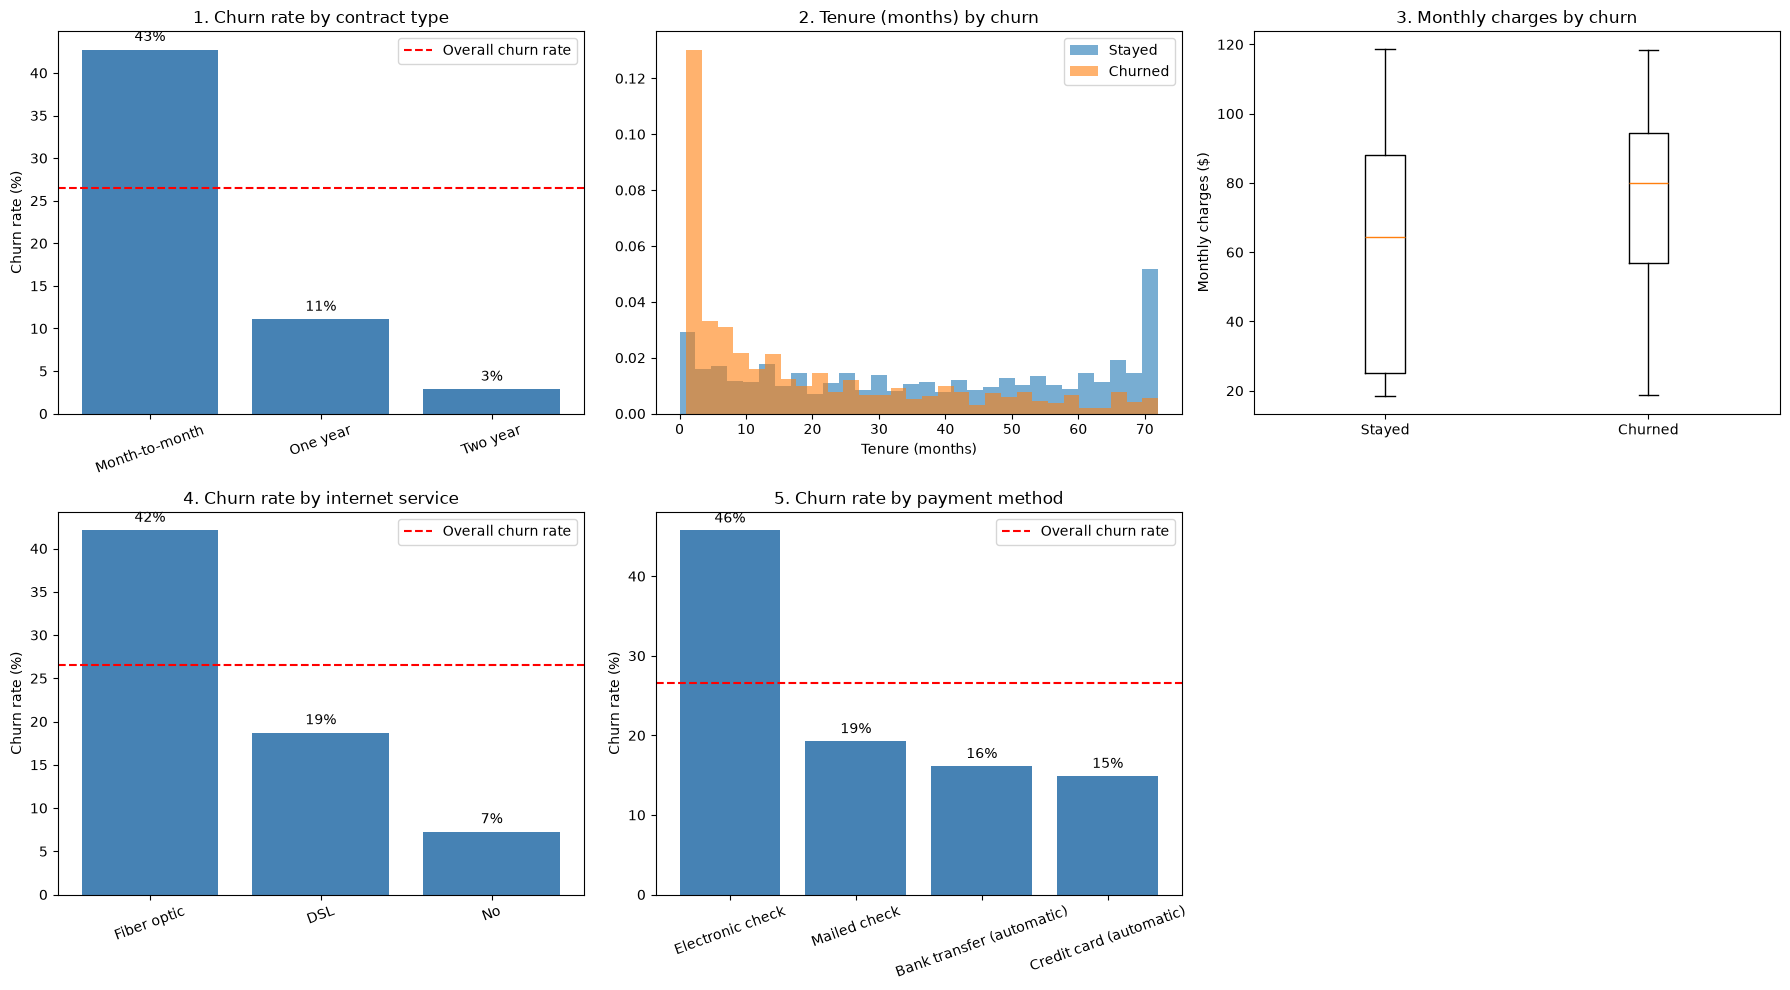

Median tenure  - stayed: 38.0 | churned: 10.0
Median monthly - stayed: 64.4 | churned: 79.95


In [3]:
def churn_rate_bar(ax, col, title):
    rate = train_df.groupby(col)["Churn"].mean().sort_values(ascending=False) * 100
    ax.bar(rate.index, rate.values, color="steelblue")
    ax.axhline(train_df["Churn"].mean() * 100, color="red", linestyle="--",
               label="Overall churn rate")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center")
    ax.set_title(title)
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend()

stay = train_df[train_df["Churn"] == 0]
left = train_df[train_df["Churn"] == 1]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Contract
churn_rate_bar(axes[0, 0], "Contract", "1. Churn rate by contract type")

# 2. Tenure
axes[0, 1].hist(stay["tenure"], bins=30, alpha=0.6, label="Stayed", density=True)
axes[0, 1].hist(left["tenure"], bins=30, alpha=0.6, label="Churned", density=True)
axes[0, 1].set_title("2. Tenure (months) by churn")
axes[0, 1].set_xlabel("Tenure (months)")
axes[0, 1].legend()

# 3. Monthly charges
axes[0, 2].boxplot([stay["MonthlyCharges"], left["MonthlyCharges"]],
                   tick_labels=["Stayed", "Churned"])
axes[0, 2].set_title("3. Monthly charges by churn")
axes[0, 2].set_ylabel("Monthly charges ($)")

# 4. Internet service
churn_rate_bar(axes[1, 0], "InternetService", "4. Churn rate by internet service")

# 5. Payment method
churn_rate_bar(axes[1, 1], "PaymentMethod", "5. Churn rate by payment method")

axes[1, 2].axis("off")     # 6th slot not needed
plt.tight_layout()
plt.savefig("eda_charts.png", dpi=150)
plt.show()

print("Median tenure  - stayed:", stay["tenure"].median(), "| churned:", left["tenure"].median())
print("Median monthly - stayed:", stay["MonthlyCharges"].median(), "| churned:", left["MonthlyCharges"].median())

### EDA findings (training data only)
1. **Contract:** month-to-month customers churn at 43%, vs 11% (one year) and 3% (two year) - the strongest pattern.
2. **Tenure:** churn is concentrated in the first months; long-tenure customers rarely leave.
3. **Monthly charges:** churners pay more (median about $80 vs $65).
4. **Internet service:** fiber optic customers churn at 42%, vs 19% (DSL) and 7% (no internet).
5. **Payment method:** electronic check users churn at 46%, vs 15-19% for other methods.

### Data checks
- 7043 rows, 21 columns, no duplicate rows. Churn rate 26.5% (imbalanced).
- TotalCharges was stored as text: 11 blank values, all for customers with tenure 0. Converted to numbers and filled with 0 (new customers have not been billed yet).
- customerID dropped (an identifier, not a feature).
- 20% test set (1409 rows) held out with stratify before EDA; it will not be used until the final step.

### Assumptions
- The data is a representative snapshot of customers; past patterns will hold for future customers.
- Each row is an independent customer.
- All features are known before a customer churns (no target leakage, unlike a "cancelled_date" column).

### Metric: ROC-AUC (primary), F1 (secondary)
- Churn is imbalanced (26.5%), so accuracy is misleading - predicting "no churn" for everyone already gives 73.5%.
- The retention team will use the model to **rank customers by churn risk** and contact the top ones, with the number contacted set by budget. ROC-AUC measures exactly this ranking ability, independent of any threshold.
- F1 will also be reported to show how well the model's yes/no predictions balance precision and recall at the chosen threshold.

## Task 2: Features and baseline models

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42,
                                     stratify=df["Churn"])
print("Train:", train_df.shape, " Test:", test_df.shape)

Train: (5634, 20)  Test: (1409, 20)


In [5]:
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def add_features(d):
    d = d.copy()
    # 1. Tenure bands
    d["tenure_group"] = pd.cut(d["tenure"], bins=[-1, 12, 24, 48, 72],
                               labels=["0-1 yr", "1-2 yr", "2-4 yr", "4-6 yr"]).astype(str)
    # 2. Average actually paid per month (new customers: use current bill)
    d["avg_monthly_spend"] = np.where(d["tenure"] > 0,
                                      d["TotalCharges"] / d["tenure"].clip(lower=1),
                                      d["MonthlyCharges"])
    # 3. Has the bill gone up compared with their average?
    d["charge_increase"] = d["MonthlyCharges"] - d["avg_monthly_spend"]
    # 4. Number of services used
    d["num_services"] = (d[service_cols] == "Yes").sum(axis=1)
    # 5. Automatic payment
    d["auto_payment"] = d["PaymentMethod"].str.contains("automatic").astype(int)
    return d

train_fe = add_features(train_df)
test_fe  = add_features(test_df)     # same formulas, nothing learned from test

new_cols = ["tenure_group", "avg_monthly_spend", "charge_increase", "num_services", "auto_payment"]
print(train_fe[new_cols].head())
print("\nShape:", train_fe.shape)

print("\nChurn rate by tenure group:")
print((train_fe.groupby("tenure_group")["Churn"].mean() * 100).round(1))
print("\nChurn rate by number of services:")
print((train_fe.groupby("num_services")["Churn"].mean() * 100).round(1))
print("\nChurn rate by auto payment (0 = manual, 1 = automatic):")
print((train_fe.groupby("auto_payment")["Churn"].mean() * 100).round(1))

     tenure_group  avg_monthly_spend  charge_increase  num_services  \
3738       2-4 yr          48.618571         0.581429             3   
3151       1-2 yr          76.770000        -1.670000             2   
4860       1-2 yr          45.411538        -4.861538             3   
3867       2-4 yr          73.296154         0.203846             5   
3810       0-1 yr          44.550000         0.000000             1   

      auto_payment  
3738             0  
3151             0  
4860             0  
3867             1  
3810             0  

Shape: (5634, 25)

Churn rate by tenure group:
tenure_group
0-1 yr    47.3
1-2 yr    28.6
2-4 yr    20.2
4-6 yr     9.9
Name: Churn, dtype: float64

Churn rate by number of services:
num_services
0    42.9
1    21.0
2    31.7
3    36.7
4    32.5
5    26.1
6    23.0
7    12.2
8     4.6
Name: Churn, dtype: float64

Churn rate by auto payment (0 = manual, 1 = automatic):
auto_payment
0    35.0
1    15.5
Name: Churn, dtype: float64


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

X_train = train_fe.drop(columns="Churn")
y_train = train_fe["Churn"]

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric columns:", len(num_cols), num_cols)
print("Categorical columns:", len(cat_cols))

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

models = {
    "Dummy (majority)":    DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", model)])
    cv = cross_validate(pipe, X_train, y_train, cv=5, scoring=["roc_auc", "f1"])
    rows.append({"Model": name,
                 "CV ROC-AUC": round(cv["test_roc_auc"].mean(), 3),
                 "CV F1":      round(cv["test_f1"].mean(), 3),
                 "F1 std":     round(cv["test_f1"].std(), 3)})

results = pd.DataFrame(rows)
print("\n", results.to_string(index=False))
results.to_csv("baseline_results.csv", index=False)     # saved for the git commit

Numeric columns: 8 ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_spend', 'charge_increase', 'num_services', 'auto_payment']
Categorical columns: 16

               Model  CV ROC-AUC  CV F1  F1 std
   Dummy (majority)       0.500  0.000   0.000
Logistic Regression       0.846  0.591   0.025
      Random Forest       0.828  0.560   0.032


### New features (5)
| Feature | Definition | Finding (train) |
|---|---|---|
| tenure_group | tenure in bands 0-1, 1-2, 2-4, 4-6 yrs | churn 47.3% → 28.6% → 20.2% → 9.9% |
| avg_monthly_spend | TotalCharges / tenure | average actually paid per month |
| charge_increase | MonthlyCharges - avg_monthly_spend | has the bill gone up recently? |
| num_services | count of services used | how "tied in" the customer is |
| auto_payment | 1 if automatic bank transfer / credit card | manual 35.0% vs automatic 15.5% churn |

All features are calculated from each customer's own row only, so applying them to the test set causes no leakage.

### Baseline results (5-fold CV on training data)
| Model | CV ROC-AUC | CV F1 |
|---|---|---|
| Dummy (majority) | 0.500 | 0.000 |
| Logistic Regression | 0.846 | 0.591 |
| Random Forest | 0.828 | 0.560 |

- Preprocessing (median imputer + scaler for 8 numeric columns; most-frequent imputer + one-hot for 16 categorical columns) runs inside the pipeline, so it is re-fitted in every CV fold - no leakage.
- Logistic Regression is the best baseline: the main churn drivers (contract, tenure, payment method) are close to linear.
- Both models clearly beat the dummy baseline (AUC 0.50). F1 is measured at the default 0.5 threshold and can be improved by threshold tuning in Part 2.